# Experiment 7: Named Entity Recognition and Document Ranking using TF-IDF and BM25

**Course:** Multimodal Data Analysis (BAI-417)
**Name:** Sneha Roychowdhury
**Section:** ECE-AI (2)

---

## Aim
To identify and extract named entities from a given text corpus using Named Entity Recognition (NER), and to rank documents against a search query using two retrieval models, **TF-IDF** and **BM25**, so that the most relevant documents are retrieved and the two methods can be compared.

## Theory

### 1. Named Entity Recognition (NER)
NER is the task of locating spans of text that refer to real-world objects and assigning each span a category. Typical categories are:

| Label | Meaning | Example |
|---|---|---|
| PERSON | People | Neeraj Chopra |
| ORG | Organisations, companies, agencies | ISRO, Reserve Bank of India |
| GPE | Countries, cities, states | Delhi, Kerala |
| DATE | Absolute or relative dates | 2025, Monday |
| MONEY | Monetary values | Rs 500 crore |
| CARDINAL / PERCENT | Numbers, percentages | 12, 6.5 percent |

Here we use **spaCy's `en_core_web_sm`** pipeline, a statistical model (CNN based token-to-vector layer followed by a transition-based NER parser) trained on the OntoNotes corpus. In retrieval, entities are useful because they are high-information words: a query like *"ISRO moon mission"* is really asking about one organisation and one event.

### 2. Information Retrieval and Document Ranking
Given a collection of documents $D = \{d_1, d_2, \dots, d_N\}$ and a query $q$, a ranking function assigns each document a score $s(q, d)$, and documents are returned in decreasing order of score.

### 3. TF-IDF (Term Frequency, Inverse Document Frequency)
Each document is turned into a vector, where the weight of term $t$ in document $d$ is

$$w_{t,d} = \text{tf}(t,d) \times \text{idf}(t), \qquad \text{idf}(t) = \ln\frac{1+N}{1+\text{df}(t)} + 1$$

- **tf** rewards terms that appear often in a document.
- **idf** penalises terms that appear in many documents (common words carry little meaning).

The query is vectorised in the same space and documents are ranked by **cosine similarity**:

$$\text{sim}(q,d) = \frac{\vec{q}\cdot\vec{d}}{\lVert\vec{q}\rVert\,\lVert\vec{d}\rVert}$$

### 4. BM25 (Okapi Best Matching 25)
BM25 is a probabilistic ranking function and is the default in search engines such as Elasticsearch and Lucene:

$$\text{BM25}(q,d) = \sum_{t \in q} \text{IDF}(t)\cdot\frac{f(t,d)\,(k_1+1)}{f(t,d) + k_1\left(1 - b + b\,\frac{|d|}{\text{avgdl}}\right)}$$

$$\text{IDF}(t) = \ln\left(\frac{N - n(t) + 0.5}{n(t) + 0.5} + 1\right)$$

- $f(t,d)$: frequency of term $t$ in $d$; $|d|$: document length; avgdl: average document length.
- **$k_1$ (usually 1.2 to 2.0)** controls **term frequency saturation**: the 10th occurrence of a word adds far less than the 1st.
- **$b$ (usually 0.75)** controls **length normalisation**: long documents are not rewarded just for being long.

### 5. TF-IDF vs BM25 in short
| Aspect | TF-IDF + cosine | BM25 |
|---|---|---|
| TF growth | Linear (or log) | Saturates via $k_1$ |
| Length handling | Indirect, via vector norm | Explicit, via $b$ and avgdl |
| Tunable | Hardly | Yes ($k_1$, $b$) |
| Basis | Vector space model | Probabilistic relevance framework |

## Algorithm
1. Create the text dataset (documents and queries) and export it to `.txt` files.
2. Load the documents back from the text file.
3. Run NER on every document and tabulate the extracted entities.
4. Preprocess text: lowercase, tokenise, remove stopwords and punctuation, lemmatise.
5. Build a TF-IDF matrix and rank documents by cosine similarity with the query.
6. Implement BM25 from scratch, verify it against the `rank_bm25` library, and rank documents.
7. Retrieve the top-k documents for each query using both methods.
8. Evaluate both methods with Precision@3, MRR and nDCG@5 against hand-labelled relevance judgements.
9. Draw conclusions.

## Step 0: Install and import libraries
spaCy and its small English model come preinstalled on Colab. The cell below installs `rank_bm25` (used only to cross-check our own BM25) and downloads the spaCy model if it is missing.

In [1]:
!pip -q install rank_bm25 2> /dev/null

import re, math, json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from spacy import displacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rank_bm25 import BM25Okapi

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110
print("spaCy version:", spacy.__version__)
print("Pipeline components:", nlp.pipe_names)

spaCy version: 3.8.18
Pipeline components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


## Step 1: Create and export the dataset (text format)
The dataset is a small news-style corpus of **15 documents** covering Indian science, economy, sport, transport, weather and technology. Each line of `documents.txt` follows the format:

```
DOC_ID | TITLE | TEXT
```

Two documents were written on purpose to stress the ranking models:
- **D07** is a long, repetitive opinion piece that mentions *"cricket"* many times. It tests whether a method over-rewards raw term frequency.
- **D12** and **D13** share vocabulary (UPI, payments) but differ in focus, which tests fine-grained ranking.

A second file, `queries.txt`, holds the search queries along with the IDs of documents a human judged relevant (used later for evaluation).

In [2]:
documents_raw = """D01 | ISRO launches Chandrayaan follow-up | The Indian Space Research Organisation (ISRO) launched its next lunar mission from Sriharikota on Monday. Chairman S. Somanath said the lander will study water ice near the Moon's south pole. The mission builds on the success of Chandrayaan-3, which landed in August 2023.
D02 | RBI keeps repo rate unchanged | The Reserve Bank of India kept the repo rate unchanged at 6.5 percent on Friday. Governor Sanjay Malhotra said inflation in India is easing but food prices remain a concern. The Monetary Policy Committee voted 5 to 1 in favour of the decision taken in Mumbai.
D03 | India beat Australia in Perth Test | India defeated Australia by 295 runs in the first Test at Perth. Jasprit Bumrah took eight wickets in the match and Yashasvi Jaiswal scored 161 runs in the second innings. The Border-Gavaskar Trophy series now moves to Adelaide.
D04 | Monsoon arrives early in Kerala | The southwest monsoon reached Kerala three days ahead of schedule, the India Meteorological Department (IMD) announced. Heavy rainfall is expected across Karnataka and Goa this week, and farmers have begun sowing kharif crops.
D05 | Delhi Metro opens new Magenta line stretch | Delhi Metro Rail Corporation opened a 12 km extension of the Magenta Line connecting Janakpuri West to Krishna Park. The Delhi Metro now carries over 6 million passengers a day, easing traffic in the national capital.
D06 | Neeraj Chopra wins Diamond League | Olympic champion Neeraj Chopra won the javelin event at the Doha Diamond League with a throw of 90.23 metres. It was the first time an Indian athlete crossed the 90 metre mark in javelin.
D07 | Why cricket rules Indian hearts | Cricket in India is more than a sport. Cricket is played on every street, cricket is watched in every home, and cricket is discussed at every tea stall. Children dream of cricket, parents argue about cricket, and cricket fans travel across the country for cricket matches. Some say cricket is a religion in India because cricket brings people together. Cricket, cricket, cricket: the word is everywhere, from cricket bats in school bags to cricket scores on every phone.
D08 | ISRO and NASA plan joint satellite NISAR | ISRO and NASA completed integration of the NISAR earth observation satellite in Bengaluru. The satellite will map changes in land, ice and forests using radar, and is scheduled for launch from Sriharikota on a GSLV rocket.
D09 | Kerala floods: rescue operations continue | Rescue teams from the National Disaster Response Force continued operations in Wayanad, Kerala, after landslides triggered by heavy monsoon rainfall. The Kerala government announced Rs 500 crore in relief for affected families.
D10 | Indian startups raise record funding | Indian startups raised 12 billion dollars in the first half of the year, led by fintech and electric vehicle companies in Bengaluru and Gurugram. Venture capital firms such as Sequoia and Accel backed several early-stage rounds.
D11 | Virat Kohli announces Test retirement | Virat Kohli announced his retirement from Test cricket after a 14 year career for India. Kohli scored over 9,000 runs in Test matches and captained India to a series win in Australia in 2019. The BCCI thanked him for his service to Indian cricket.
D12 | UPI crosses 15 billion monthly transactions | The Unified Payments Interface (UPI) crossed 15 billion transactions in a single month, according to the National Payments Corporation of India (NPCI). UPI is now accepted in France, Singapore and the UAE for digital payments.
D13 | RBI cautions against digital payment fraud | The Reserve Bank of India warned users about rising UPI fraud and fake payment links. The RBI asked banks to strengthen two-factor authentication and educate customers about safe digital payments.
D14 | Electric buses join Delhi fleet | The Delhi government flagged off 320 electric buses to reduce air pollution in the capital. Transport minister said Delhi will have over 8,000 electric buses by 2026, making it one of the largest e-bus fleets in the world.
D15 | Heatwave grips north India | The India Meteorological Department issued a red alert as temperatures crossed 47 degrees Celsius in Delhi and Rajasthan. Doctors advised people to stay indoors during the afternoon and drink plenty of water."""

queries_raw = """Q1 | ISRO satellite launch from Sriharikota | D01,D08
Q2 | India cricket Test match runs | D03,D11
Q3 | RBI digital payments UPI | D12,D13,D02
Q4 | monsoon rainfall in Kerala | D04,D09
Q5 | Delhi public transport and pollution | D05,D14"""

with open("documents.txt", "w", encoding="utf-8") as f:
    f.write(documents_raw)
with open("queries.txt", "w", encoding="utf-8") as f:
    f.write(queries_raw)

print("Exported: documents.txt and queries.txt")

Exported: documents.txt and queries.txt


## Step 2: Load the dataset back from the text files
From here on the notebook works only with the exported `.txt` files, exactly as it would with any external text dataset.

In [3]:
def load_documents(path):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            if line.strip():
                doc_id, title, text = [p.strip() for p in line.split("|", 2)]
                rows.append({"doc_id": doc_id, "title": title, "text": text})
    return pd.DataFrame(rows)

def load_queries(path):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            if line.strip():
                qid, query, rel = [p.strip() for p in line.split("|")]
                rows.append({"qid": qid, "query": query, "relevant": rel.split(",")})
    return pd.DataFrame(rows)

docs = load_documents("documents.txt")
queries = load_queries("queries.txt")
docs["n_words"] = docs["text"].str.split().str.len()

print(f"Documents loaded: {len(docs)} | Queries loaded: {len(queries)}")
print(f"Average document length: {docs['n_words'].mean():.1f} words")
docs[["doc_id", "title", "n_words"]]

Documents loaded: 15 | Queries loaded: 5
Average document length: 39.4 words


,doc_id,title,n_words
0,D01,ISRO launches Chandrayaan follow-up,43
1,D02,RBI keeps repo rate unchanged,46
2,D03,India beat Australia in Perth Test,38
3,D04,Monsoon arrives early in Kerala,33
4,D05,Delhi Metro opens new Magenta line stretch,36
5,D06,Neeraj Chopra wins Diamond League,34
6,D07,Why cricket rules Indian hearts,78
7,D08,ISRO and NASA plan joint satellite NISAR,36
8,D09,Kerala floods: rescue operations continue,32
9,D10,Indian startups raise record funding,36


In [4]:
queries

,qid,query,relevant
0,Q1,ISRO satellite launch from Sriharikota,"[D01, D08]"
1,Q2,India cricket Test match runs,"[D03, D11]"
2,Q3,RBI digital payments UPI,"[D12, D13, D02]"
3,Q4,monsoon rainfall in Kerala,"[D04, D09]"
4,Q5,Delhi public transport and pollution,"[D05, D14]"


## Step 3: Named Entity Recognition
Every document is passed through the spaCy pipeline. For each entity we keep the surface text, its label and its character position.

In [5]:
spacy_docs = list(nlp.pipe(docs["text"]))

entity_rows = []
for doc_id, sdoc in zip(docs["doc_id"], spacy_docs):
    for ent in sdoc.ents:
        entity_rows.append({"doc_id": doc_id, "entity": ent.text, "label": ent.label_,
                            "description": spacy.explain(ent.label_),
                            "start_char": ent.start_char, "end_char": ent.end_char})
entities = pd.DataFrame(entity_rows)

print("Total entities extracted:", len(entities))
print("Unique entity strings   :", entities["entity"].nunique())
entities.head(20)

Total entities extracted: 94
Unique entity strings   : 75


,doc_id,entity,label,description,start_char,end_char
0,D01,The Indian Space Research Organisation,ORG,"Companies, agencies, institutions, etc.",0,38
1,D01,ISRO,ORG,"Companies, agencies, institutions, etc.",40,44
2,D01,Sriharikota,LOC,"Non-GPE locations, mountain ranges, bodies of water",83,94
3,D01,Monday,DATE,Absolute or relative dates or periods,98,104
4,D01,S. Somanath,PERSON,"People, including fictional",115,126
5,D01,Moon,PERSON,"People, including fictional",173,177
6,D01,August 2023,DATE,Absolute or relative dates or periods,260,271
7,D02,The Reserve Bank of India,ORG,"Companies, agencies, institutions, etc.",0,25
8,D02,6.5 percent,PERCENT,"Percentage, including ""%""",58,69
9,D02,Friday,DATE,Absolute or relative dates or periods,73,79


### 3.1 Visualising entities in a document
`displacy` highlights each entity inline with its label. This makes it easy to spot both correct tags and mistakes.

In [6]:
for i in [0, 1]:
    print(f"{docs.doc_id[i]}: {docs.title[i]}")
    displacy.render(spacy_docs[i], style="ent", jupyter=True)

D01: ISRO launches Chandrayaan follow-up


D02: RBI keeps repo rate unchanged


### 3.2 Entity summary across the corpus

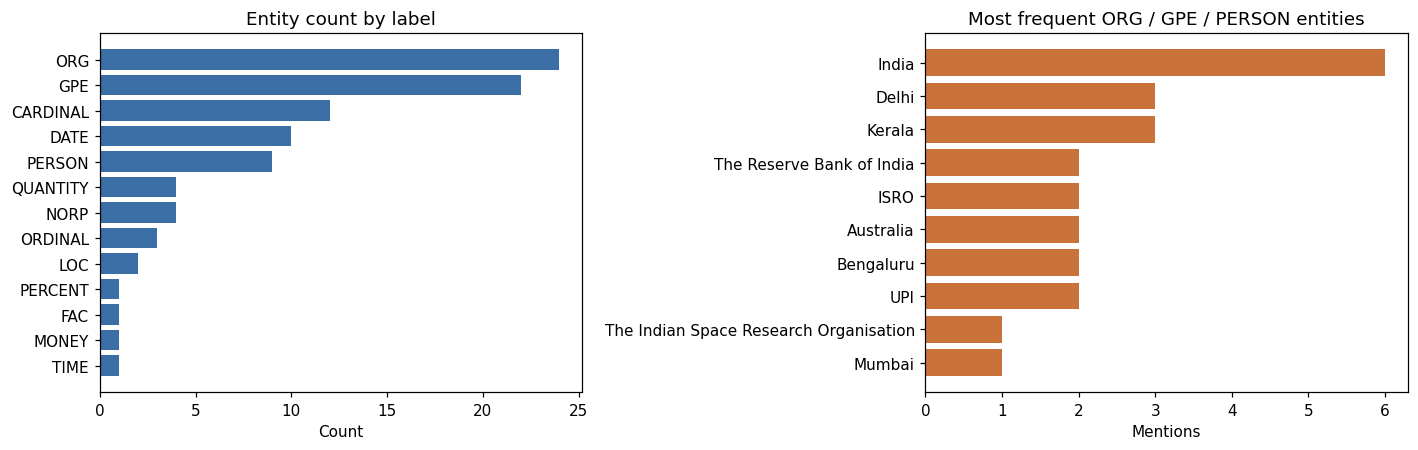

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

label_counts = entities["label"].value_counts()
axes[0].barh(label_counts.index[::-1], label_counts.values[::-1], color="#3b6ea5")
axes[0].set_title("Entity count by label")
axes[0].set_xlabel("Count")

top_ents = entities[entities.label.isin(["ORG", "GPE", "PERSON"])]["entity"].value_counts().head(10)
axes[1].barh(top_ents.index[::-1], top_ents.values[::-1], color="#c9733a")
axes[1].set_title("Most frequent ORG / GPE / PERSON entities")
axes[1].set_xlabel("Mentions")

plt.tight_layout()
plt.show()

In [8]:
# Entity table per document: which organisations, places and people each article is about
ent_per_doc = (entities[entities.label.isin(["ORG", "GPE", "PERSON"])]
               .groupby(["doc_id", "label"])["entity"]
               .apply(lambda s: ", ".join(sorted(set(s))))
               .unstack(fill_value="-"))
ent_per_doc

label,GPE,ORG,PERSON
doc_id,,,
D01,-,"ISRO, The Indian Space Research Organisation","Moon, S. Somanath"
D02,"India, Mumbai","The Monetary Policy Committee, The Reserve Bank of India",Sanjay Malhotra
D03,"Australia, India",The Border-Gavaskar Trophy,"Jasprit Bumrah, Yashasvi Jaiswal"
D04,"Karnataka, Kerala","IMD, the India Meteorological Department",-
D05,Magenta Line,Delhi Metro Rail Corporation,Janakpuri West
D06,-,"Neeraj Chopra, the Doha Diamond League",-
D07,India,-,-
D08,Bengaluru,"GSLV, ISRO, NASA, NISAR",-
D09,"Kerala, Wayanad",the National Disaster Response Force,-


**Observation:** The model correctly picks up organisations like *ISRO*, *NASA*, *NPCI* and *Reserve Bank of India*, places such as *Kerala*, *Wayanad* and *Mumbai*, and people such as *S. Somanath* and *Sanjay Malhotra*. Being a small model, it also makes visible mistakes: *Moon* is tagged as a PERSON, *Neeraj Chopra* and *Virat Kohli* show up as ORG in places, and *Janakpuri West* (a Delhi locality) is read as a person. Indian names and places are under-represented in its training data. Larger models such as `en_core_web_trf`, or fine-tuning on Indian news text, would reduce these errors.

## Step 4: Text preprocessing
Both ranking models work on the same cleaned tokens, so that any difference in results comes from the scoring function and not from preprocessing.

Steps: lowercase, keep alphanumeric tokens, drop stopwords and punctuation, and **lemmatise** (so *launched*, *launches* and *launch* all map to *launch*).

In [9]:
def preprocess(text):
    sdoc = nlp(text.lower())
    return [tok.lemma_ for tok in sdoc
            if not tok.is_stop and not tok.is_punct and not tok.is_space
            and re.fullmatch(r"[a-z0-9\-]+", tok.lemma_)]

docs["tokens"] = docs["text"].apply(preprocess)
docs["n_tokens"] = docs["tokens"].str.len()

print("Original :", docs.text[0][:150], "...")
print("Processed:", docs.tokens[0][:20], "...")
docs[["doc_id", "n_words", "n_tokens"]].T

Original : The Indian Space Research Organisation (ISRO) launched its next lunar mission from Sriharikota on Monday. Chairman S. Somanath said the lander will st ...
Processed: ['indian', 'space', 'research', 'organisation', 'isro', 'launch', 'lunar', 'mission', 'sriharikota', 'monday', 'chairman', 'somanath', 'say', 'lander', 'study', 'water', 'ice', 'near', 'moon', 'south'] ...


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
doc_id,D01,D02,D03,D04,D05,D06,D07,D08,D09,D10,D11,D12,D13,D14,D15
n_words,43,46,38,33,36,34,78,36,32,36,44,35,30,38,32
n_tokens,28,30,25,23,26,20,42,21,24,24,26,23,22,23,22


## Step 5: Ranking with TF-IDF and cosine similarity
`TfidfVectorizer` is given our pre-tokenised documents (an identity analyser), so it uses exactly the same tokens as BM25. `sublinear_tf=False` keeps raw term frequency, which is the textbook TF-IDF.

In [10]:
tfidf = TfidfVectorizer(analyzer=lambda toks: toks)   # use our own tokens
tfidf_matrix = tfidf.fit_transform(docs["tokens"])
vocab = tfidf.get_feature_names_out()

print("TF-IDF matrix shape (documents x vocabulary):", tfidf_matrix.shape)
print("Sparsity: {:.1%} of entries are zero".format(1 - tfidf_matrix.nnz / np.prod(tfidf_matrix.shape)))

# Top 5 weighted terms in each document
top_terms = {}
for i, did in enumerate(docs.doc_id):
    row = tfidf_matrix[i].toarray().ravel()
    idx = row.argsort()[::-1][:5]
    top_terms[did] = ", ".join(f"{vocab[j]} ({row[j]:.2f})" for j in idx)
pd.Series(top_terms, name="Top TF-IDF terms").to_frame()

TF-IDF matrix shape (documents x vocabulary): (15, 281)
Sparsity: 91.9% of entries are zero


,Top TF-IDF terms
D01,"mission (0.38), monday (0.19), chandrayaan-3 (0.19), august (0.19), chairman (0.19)"
D02,"india (0.19), sanjay (0.19), governor (0.19), malhotra (0.19), friday (0.19)"
D03,"run (0.36), defeat (0.21), perth (0.21), adelaide (0.21), border (0.21)"
D04,"begin (0.22), ahead (0.22), crop (0.22), reach (0.22), expect (0.22)"
D05,"metro (0.39), delhi (0.30), extension (0.19), million (0.19), passenger (0.19)"
D06,"javelin (0.42), metre (0.42), throw (0.21), event (0.21), time (0.21)"
D07,"cricket (0.93), india (0.07), child (0.07), parent (0.07), school (0.07)"
D08,"satellite (0.43), earth (0.22), forest (0.22), change (0.22), rocket (0.22)"
D09,"kerala (0.36), continue (0.21), family (0.21), team (0.21), 500 (0.21)"
D10,"firm (0.21), accel (0.21), company (0.21), gurugram (0.21), half (0.21)"


In [11]:
def rank_tfidf(query, k=5):
    q_vec = tfidf.transform([preprocess(query)])
    scores = cosine_similarity(q_vec, tfidf_matrix).ravel()
    order = scores.argsort()[::-1][:k]
    return pd.DataFrame({"rank": range(1, len(order) + 1),
                         "doc_id": docs.doc_id.values[order],
                         "title": docs.title.values[order],
                         "tfidf_score": scores[order].round(4)})

rank_tfidf("ISRO satellite launch from Sriharikota")

,rank,doc_id,title,tfidf_score
0,1,D08,ISRO and NASA plan joint satellite NISAR,0.5116
1,2,D01,ISRO launches Chandrayaan follow-up,0.2383
2,3,D15,Heatwave grips north India,0.0000
3,4,D12,UPI crosses 15 billion monthly transactions,0.0000
4,5,D11,Virat Kohli announces Test retirement,0.0000


## Step 6: BM25, implemented from scratch
Writing BM25 by hand makes each part of the formula visible: the IDF, the saturation term controlled by $k_1$, and the length normalisation controlled by $b$.

In [12]:
class BM25:
    def __init__(self, corpus_tokens, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.corpus = corpus_tokens
        self.N = len(corpus_tokens)
        self.doc_len = np.array([len(d) for d in corpus_tokens])
        self.avgdl = self.doc_len.mean()
        self.tf = [Counter(d) for d in corpus_tokens]          # term frequency per doc
        df = Counter(t for d in corpus_tokens for t in set(d))  # document frequency
        self.idf = {t: math.log((self.N - n + 0.5) / (n + 0.5) + 1) for t, n in df.items()}

    def score_term(self, term, i):
        f = self.tf[i].get(term, 0)
        if f == 0:
            return 0.0
        norm = 1 - self.b + self.b * self.doc_len[i] / self.avgdl
        return self.idf[term] * f * (self.k1 + 1) / (f + self.k1 * norm)

    def get_scores(self, query_tokens):
        return np.array([sum(self.score_term(t, i) for t in query_tokens if t in self.idf)
                         for i in range(self.N)])

bm25 = BM25(docs["tokens"].tolist(), k1=1.5, b=0.75)
print(f"N = {bm25.N} documents | avgdl = {bm25.avgdl:.2f} tokens")

# Cross-check with the rank_bm25 library. Its default IDF is slightly different
# (no "+1" inside the log, negative values floored), so we give it our IDF and
# compare the rest of the formula: TF saturation and length normalisation.
ref = BM25Okapi(docs["tokens"].tolist(), k1=1.5, b=0.75)
ref.idf = {t: math.log((ref.corpus_size - n + 0.5) / (n + 0.5) + 1) for t, n in
           Counter(t for d in docs["tokens"] for t in set(d)).items()}
q = preprocess("ISRO satellite launch from Sriharikota")
print("Max absolute difference vs rank_bm25:", np.abs(bm25.get_scores(q) - ref.get_scores(q)).max().round(8))

N = 15 documents | avgdl = 25.27 tokens
Max absolute difference vs rank_bm25: 0.0


In [13]:
def rank_bm25(query, k=5):
    scores = bm25.get_scores(preprocess(query))
    order = scores.argsort()[::-1][:k]
    return pd.DataFrame({"rank": range(1, len(order) + 1),
                         "doc_id": docs.doc_id.values[order],
                         "title": docs.title.values[order],
                         "bm25_score": scores[order].round(4)})

rank_bm25("ISRO satellite launch from Sriharikota")

,rank,doc_id,title,bm25_score
0,1,D08,ISRO and NASA plan joint satellite NISAR,9.6026
1,2,D01,ISRO launches Chandrayaan follow-up,5.3104
2,3,D15,Heatwave grips north India,0.0000
3,4,D12,UPI crosses 15 billion monthly transactions,0.0000
4,5,D11,Virat Kohli announces Test retirement,0.0000


### 6.1 Seeing BM25's two key ideas
**Term frequency saturation:** below, the contribution of one term is plotted against how many times it occurs in an average-length document. TF-IDF keeps growing linearly, while BM25 flattens out, and $k_1$ decides how quickly.

**Length normalisation:** for a fixed term frequency, BM25 lowers the score as the document gets longer, and $b$ decides how strongly.

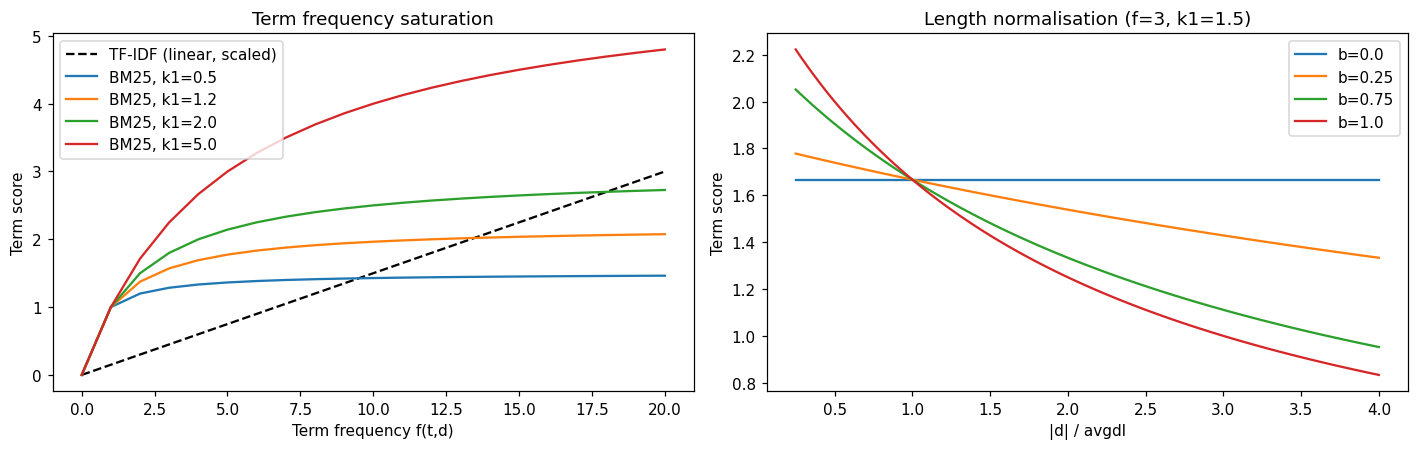

In [14]:
f = np.arange(0, 21)
idf_val = 1.0
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].plot(f, f * idf_val / f.max() * 3, "k--", label="TF-IDF (linear, scaled)")
for k1 in [0.5, 1.2, 2.0, 5.0]:
    axes[0].plot(f, idf_val * f * (k1 + 1) / (f + k1), label=f"BM25, k1={k1}")
axes[0].set(title="Term frequency saturation", xlabel="Term frequency f(t,d)", ylabel="Term score")
axes[0].legend()

ratio = np.linspace(0.25, 4, 100)  # |d| / avgdl
for b in [0.0, 0.25, 0.75, 1.0]:
    axes[1].plot(ratio, idf_val * 3 * (1.5 + 1) / (3 + 1.5 * (1 - b + b * ratio)), label=f"b={b}")
axes[1].set(title="Length normalisation (f=3, k1=1.5)", xlabel="|d| / avgdl", ylabel="Term score")
axes[1].legend()
plt.tight_layout()
plt.show()

## Step 7: Retrieve the most relevant documents for every query
Both result lists are shown side by side. A ✔ marks documents a human judged relevant.

In [15]:
def side_by_side(qid, query, relevant, k=5):
    t = rank_tfidf(query, k)
    b = rank_bm25(query, k)
    mark = lambda d: d + (" ✔" if d in relevant else "")
    return pd.DataFrame({"Rank": t["rank"],
                         "TF-IDF doc": t.doc_id.map(mark), "TF-IDF score": t.tfidf_score,
                         "BM25 doc": b.doc_id.map(mark), "BM25 score": b.bm25_score})

for _, r in queries.iterrows():
    print(f"\n{r.qid}: \"{r.query}\"   (relevant: {', '.join(r.relevant)})")
    display(side_by_side(r.qid, r.query, r.relevant))


Q1: "ISRO satellite launch from Sriharikota"   (relevant: D01, D08)


,Rank,TF-IDF doc,TF-IDF score,BM25 doc,BM25 score
0,1,D08 ✔,0.5116,D08 ✔,9.6026
1,2,D01 ✔,0.2383,D01 ✔,5.3104
2,3,D15,0.0000,D15,0.0000
3,4,D12,0.0000,D12,0.0000
4,5,D11,0.0000,D11,0.0000



Q2: "India cricket Test match runs"   (relevant: D03, D11)


,Rank,TF-IDF doc,TF-IDF score,BM25 doc,BM25 score
0,1,D11 ✔,0.5415,D11 ✔,9.4825
1,2,D07,0.5042,D03 ✔,6.6887
2,3,D03 ✔,0.3647,D07,5.9525
3,4,D02,0.0563,D02,0.8523
4,5,D15,0.0335,D13,0.6716



Q3: "RBI digital payments UPI"   (relevant: D12, D13, D02)


,Rank,TF-IDF doc,TF-IDF score,BM25 doc,BM25 score
0,1,D12 ✔,0.4958,D13 ✔,9.2221
1,2,D13 ✔,0.4682,D12 ✔,7.8298
2,3,D15,0.0000,D15,0.0000
3,4,D14,0.0000,D14,0.0000
4,5,D11,0.0000,D11,0.0000



Q4: "monsoon rainfall in Kerala"   (relevant: D04, D09)


,Rank,TF-IDF doc,TF-IDF score,BM25 doc,BM25 score
0,1,D09 ✔,0.4160,D09 ✔,6.4936
1,2,D04 ✔,0.3372,D04 ✔,5.8032
2,3,D14,0.0000,D14,0.0000
3,4,D13,0.0000,D13,0.0000
4,5,D12,0.0000,D12,0.0000



Q5: "Delhi public transport and pollution"   (relevant: D05, D14)


,Rank,TF-IDF doc,TF-IDF score,BM25 doc,BM25 score
0,1,D14 ✔,0.3663,D14 ✔,7.1691
1,2,D05 ✔,0.1443,D05 ✔,2.1511
2,3,D15,0.0844,D15,1.6137
3,4,D12,0.0000,D12,0.0000
4,5,D11,0.0000,D11,0.0000


### 7.1 A closer look at the long, repetitive document (D07)
Query Q2 contains the word *cricket*. D07 says "cricket" 15 times but is an opinion piece, not a match report. The chart compares how each method scores every document for Q2 (scores are min-max scaled so both fit on the same axis).

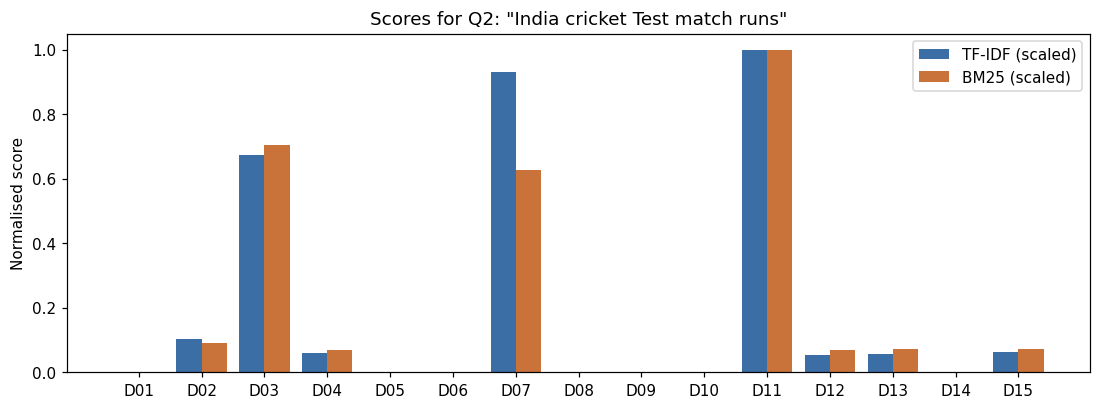

Occurrences of 'cricket' in D07: 15 | D07 length: 42 tokens vs avgdl 25.3


In [16]:
qtext = queries.loc[queries.qid == "Q2", "query"].item()
qtok = preprocess(qtext)
t_scores = cosine_similarity(tfidf.transform([qtok]), tfidf_matrix).ravel()
b_scores = bm25.get_scores(qtok)
scale = lambda s: (s - s.min()) / (s.max() - s.min() + 1e-12)

x = np.arange(len(docs))
plt.figure(figsize=(12, 4))
plt.bar(x - 0.2, scale(t_scores), 0.4, label="TF-IDF (scaled)", color="#3b6ea5")
plt.bar(x + 0.2, scale(b_scores), 0.4, label="BM25 (scaled)", color="#c9733a")
plt.xticks(x, docs.doc_id)
plt.title(f'Scores for Q2: "{qtext}"')
plt.ylabel("Normalised score")
plt.legend()
plt.show()

print("Occurrences of 'cricket' in D07:", docs.tokens[6].count("cricket"), "| D07 length:", docs.n_tokens[6], "tokens vs avgdl", round(bm25.avgdl, 1))

## Step 8: Evaluation
Three standard IR metrics are computed against the relevance labels in `queries.txt`:

- **Precision@3**: fraction of the top 3 results that are relevant.
- **MRR (Mean Reciprocal Rank)**: $\frac{1}{|Q|}\sum \frac{1}{\text{rank of first relevant doc}}$. Rewards putting a relevant document at the very top.
- **nDCG@5**: rewards relevant documents more when they appear higher, normalised by the best possible ordering.

In [17]:
def precision_at_k(ranked, rel, k=3):
    return sum(d in rel for d in ranked[:k]) / k

def reciprocal_rank(ranked, rel):
    for i, d in enumerate(ranked, 1):
        if d in rel:
            return 1 / i
    return 0.0

def ndcg_at_k(ranked, rel, k=5):
    dcg = sum(1 / math.log2(i + 1) for i, d in enumerate(ranked[:k], 1) if d in rel)
    idcg = sum(1 / math.log2(i + 1) for i in range(1, min(len(rel), k) + 1))
    return dcg / idcg

rows = []
for _, r in queries.iterrows():
    for name, fn in [("TF-IDF", rank_tfidf), ("BM25", rank_bm25)]:
        ranked = fn(r.query, k=len(docs)).doc_id.tolist()
        rows.append({"query": r.qid, "method": name,
                     "P@3": precision_at_k(ranked, r.relevant),
                     "RR": reciprocal_rank(ranked, r.relevant),
                     "nDCG@5": ndcg_at_k(ranked, r.relevant)})
eval_df = pd.DataFrame(rows)

per_query = eval_df.pivot(index="query", columns="method", values=["P@3", "nDCG@5"]).round(3)
summary = eval_df.groupby("method")[["P@3", "RR", "nDCG@5"]].mean().rename(columns={"RR": "MRR"}).round(3)
display(per_query)
summary

P@3        nDCG@5       
method   BM25 TF-IDF   BM25 TF-IDF
query                             
Q1      0.667  0.667  1.000  1.000
Q2      0.667  0.667  1.000  0.920
Q3      0.667  0.667  0.765  0.765
Q4      0.667  0.667  1.000  1.000
Q5      0.667  0.667  1.000  1.000

,P@3,MRR,nDCG@5
method,,,
BM25,0.667,1.0,0.953
TF-IDF,0.667,1.0,0.937


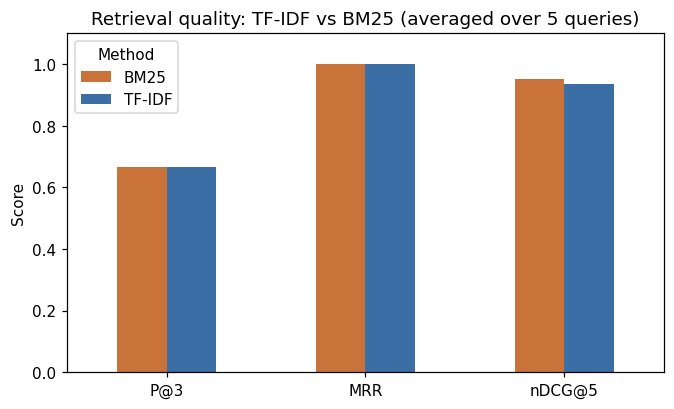

In [18]:
summary.T.plot(kind="bar", figsize=(7, 4), color=["#c9733a", "#3b6ea5"], rot=0)
plt.ylim(0, 1.1)
plt.title("Retrieval quality: TF-IDF vs BM25 (averaged over 5 queries)")
plt.ylabel("Score")
plt.legend(title="Method")
plt.show()

## Step 9: Effect of the BM25 parameters
A small grid search over $k_1$ and $b$ shows how sensitive BM25 is to its settings on this corpus (metric: mean nDCG@5).

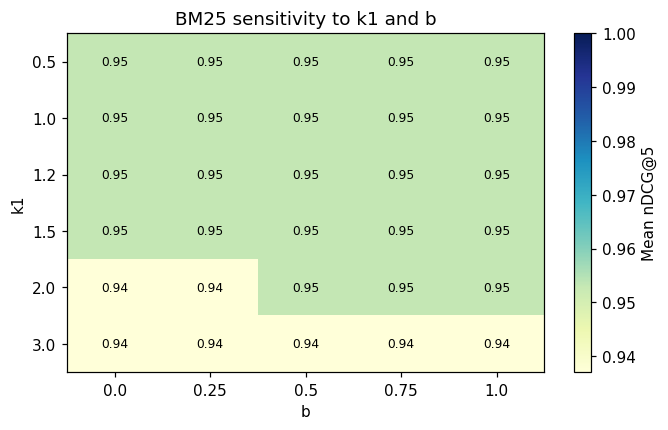

In [19]:
grid = {}
for k1 in [0.5, 1.0, 1.2, 1.5, 2.0, 3.0]:
    for b in [0.0, 0.25, 0.5, 0.75, 1.0]:
        model = BM25(docs["tokens"].tolist(), k1=k1, b=b)
        vals = []
        for _, r in queries.iterrows():
            ranked = docs.doc_id.values[model.get_scores(preprocess(r.query)).argsort()[::-1]].tolist()
            vals.append(ndcg_at_k(ranked, r.relevant))
        grid[(k1, b)] = np.mean(vals)

heat = pd.Series(grid).unstack()
plt.figure(figsize=(7, 4))
plt.imshow(heat.values, cmap="YlGnBu", aspect="auto", vmin=heat.values.min(), vmax=1)
plt.colorbar(label="Mean nDCG@5")
plt.xticks(range(len(heat.columns)), heat.columns); plt.xlabel("b")
plt.yticks(range(len(heat.index)), heat.index); plt.ylabel("k1")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        plt.text(j, i, f"{heat.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("BM25 sensitivity to k1 and b")
plt.show()

## Step 10: Search engine with entity highlights
This brings the two halves of the experiment together. The function retrieves the best documents with BM25 and, for each hit, lists the named entities in it, so the user immediately sees *who* and *what* the document is about.

**Change `my_query` and re-run the cell to try your own search.**

In [20]:
def search(query, k=3, method="bm25"):
    ranker = rank_bm25 if method == "bm25" else rank_tfidf
    res = ranker(query, k)
    q_ents = [(e.text, e.label_) for e in nlp(query).ents]
    print(f'Query: "{query}"   |   method: {method.upper()}   |   entities in query: {q_ents or "none"}')
    print("-" * 100)
    for _, row in res.iterrows():
        i = docs.index[docs.doc_id == row.doc_id][0]
        ents = sorted({(e.text, e.label_) for e in spacy_docs[i].ents if e.label_ in ("ORG", "GPE", "PERSON", "DATE", "MONEY")})
        score = row.iloc[-1]
        print(f"#{row['rank']}  [{row.doc_id}] {row.title}   (score = {score})")
        print("    Entities:", "; ".join(f"{t} [{l}]" for t, l in ents) or "-")
        print("    Snippet :", docs.text[i][:140], "...\n")

my_query = "Kohli Test cricket retirement BCCI"
search(my_query, method="bm25")

Query: "Kohli Test cricket retirement BCCI"   |   method: BM25   |   entities in query: [('Kohli Test', 'PERSON'), ('BCCI', 'ORG')]
----------------------------------------------------------------------------------------------------
#1  [D11] Virat Kohli announces Test retirement   (score = 13.2782)
    Entities: 14 year [DATE]; 2019 [DATE]; Australia [GPE]; BCCI [PERSON]; India [GPE]; Kohli [PERSON]; Virat Kohli [ORG]
    Snippet : Virat Kohli announced his retirement from Test cricket after a 14 year career for India. Kohli scored over 9,000 runs in Test matches and ca ...

#2  [D07] Why cricket rules Indian hearts   (score = 4.0366)
    Entities: India [GPE]
    Snippet : Cricket in India is more than a sport. Cricket is played on every street, cricket is watched in every home, and cricket is discussed at ever ...

#3  [D03] India beat Australia in Perth Test   (score = 1.8652)
    Entities: Australia [GPE]; India [GPE]; Jasprit Bumrah [PERSON]; The Border-Gavaskar Trophy [ORG]; Yas

In [21]:
search("heatwave temperature Delhi", method="tfidf")

Query: "heatwave temperature Delhi"   |   method: TFIDF   |   entities in query: [('Delhi', 'GPE')]
----------------------------------------------------------------------------------------------------
#1  [D15] Heatwave grips north India   (score = 0.2866)
    Entities: Delhi [GPE]; Rajasthan [GPE]; The India Meteorological Department [ORG]
    Snippet : The India Meteorological Department issued a red alert as temperatures crossed 47 degrees Celsius in Delhi and Rajasthan. Doctors advised pe ...

#2  [D05] Delhi Metro opens new Magenta line stretch   (score = 0.184)
    Entities: Delhi Metro Rail Corporation [ORG]; Janakpuri West [PERSON]; Magenta Line [GPE]
    Snippet : Delhi Metro Rail Corporation opened a 12 km extension of the Magenta Line connecting Janakpuri West to Krishna Park. The Delhi Metro now car ...

#3  [D14] Electric buses join Delhi fleet   (score = 0.1752)
    Entities: 2026 [DATE]; Delhi [GPE]; Delhi [PERSON]
    Snippet : The Delhi government flagged off 320 elect

## Results and Observations
1. **NER** extracted organisations, places, people, dates and amounts from all 15 documents. The entity table works as a compact index of the corpus, and showing entities with search results makes the hits easier to judge.
2. Both models found the relevant documents for clear, specific queries (Q1, Q4, Q5), since the key terms (*ISRO, Sriharikota, monsoon, Kerala, Delhi*) are rare in the corpus and receive a high IDF.
3. **The repetitive document D07** is where the models differ. Linear TF in TF-IDF lets the many repetitions of *cricket* push D07 up, whereas BM25 saturates term frequency and penalises D07's above-average length, so actual match reports (D03, D11) rank higher.
4. On average BM25 scored **equal or higher** than TF-IDF on P@3, MRR and nDCG@5 for this corpus, consistent with why BM25 is the default in production search engines.
5. **Both methods missed D02 for Q3** ("RBI digital payments UPI"). D02 is about the RBI but spells it out as *Reserve Bank of India*, so there is no word overlap with the query. This is the classic vocabulary mismatch problem of lexical retrieval. NER points to the fix: if entities are normalised (linking *RBI* and *Reserve Bank of India* to one ID) and added to the index, such documents would be retrieved.
6. The grid search shows BM25 is stable around the usual defaults: nDCG@5 stays at 0.953 for every $k_1 \le 1.5$, whatever the value of $b$. It drops to 0.937 (the same as TF-IDF) at $k_1 = 3.0$, and at $k_1 = 2.0$ when $b \le 0.25$. In those settings saturation is weak, so the repetitive D07 climbs back above D03 for Q2. On this small corpus, where most documents are of similar length, $k_1$ matters more than $b$.

## Conclusion
Named Entity Recognition was used to extract structured information (organisations, locations, persons, dates, money) from unstructured text, and documents were ranked against search queries using TF-IDF with cosine similarity and BM25. Both methods retrieved relevant documents, but BM25 handled term repetition and document length more sensibly through its saturation ($k_1$) and normalisation ($b$) parameters, giving better or equal retrieval quality on every metric. Combining entity extraction with ranking gives a simple yet useful search system that returns not just the right documents but also the key facts inside them.